In [ ]:
# Importación de librerías
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [ ]:
# Parámetros físicos del Robot Angular RRR
# Valores propuestos para un manipulador articulado de laboratorio
m1 = 2.0   # masa de la columna base (kg)
m2 = 1.5   # masa del eslabón 2 (kg)
m3 = 1.0   # masa del eslabón 3 (kg)
l1 = 0.5   # altura de la columna 1 (m)
l2 = 0.6   # longitud del eslabón 2 (m)
l3 = 0.5   # longitud del eslabón 3 (m)
g  = 9.81  # aceleración gravitatoria (m/s^2)

# Constantes inerciales fijas
M22 = (m2 / 4.0 + m3) * l2**2
M33 = (m3 * l3**2) / 4.0

In [ ]:
# Modelo dinámico
def obtener_matrices(q, qd):
    q1, q2, q3 = q
    qd1, qd2, qd3 = qd

    # Radios horizontales
    rho2 = (l2 / 2.0) * np.sin(q2)
    rho3 = l2 * np.sin(q2) + (l3 / 2.0) * np.sin(q3)

    # Matriz de Inercia M(q)
    M11 = m2 * rho2**2 + m3 * rho3**2
    M23 = 0.5 * m3 * l2 * l3 * np.cos(q2 - q3)

    M = np.array([
        [M11, 0.0, 0.0],
        [0.0, M22, M23],
        [0.0, M23, M33]
    ])

    # Variables auxiliares y matriz de Coriolis C(q, qd)
    a = (m2 / 4.0 + m3) * l2**2 * np.sin(2.0 * q2) + m3 * l2 * l3 * np.cos(q2) * np.sin(q3)
    b = m3 * l2 * l3 * np.sin(q2) * np.cos(q3) + (m3 * l3**2 / 4.0) * np.sin(2.0 * q3)
    e = 0.5 * m3 * l2 * l3 * np.sin(q2 - q3)

    C = np.array([
        [0.5 * (a * qd2 + b * qd3),  0.5 * a * qd1,  0.5 * b * qd1],
        [-0.5 * a * qd1,             0.0,            e * qd3      ],
        [-0.5 * b * qd1,            -e * qd2,        0.0          ]
    ])

    # Vector de gravedad G(q)
    G = np.array([
        0.0,
        g * (m2 / 2.0 + m3) * l2 * np.sin(q2),
        0.5 * m3 * g * l3 * np.sin(q3)
    ])

    return M, C, G

def modelo_robot_rrr(x, t, tau):
    # Vector de estado de 6 variables: x = [q1, q2, q3, qd1, qd2, qd3]
    q  = x[:3]
    qd = x[3:]

    M, C, G = obtener_matrices(q, qd)

    # Regularización numérica mínima en M11 solo si q2=0 y q3=0 exactos
    if M[0, 0] < 1e-8:
        M[0, 0] = 1e-8

    # Despeje de aceleraciones
    rhs = tau - (C @ qd) - G
    qdd = np.linalg.solve(M, rhs)

    return np.concatenate((qd, qdd))

In [ ]:
# Simulación de dos condiciones iniciales y análisis dinámico
t = np.linspace(0, 5, 1000)  # Simulación de 0 a 5 segundos

# Brazo extendido (q2=60°, q3=30°) en caída libre (tau = [0, 0, 0])
x0_1  = [0.0, np.radians(60), np.radians(30), 0.0, 0.0, 0.0]
tau_1 = np.array([0.0, 0.0, 0.0])
sol_1 = odeint(modelo_robot_rrr, x0_1, t, args=(tau_1,))

# Posición elevada (q1=15°, q2=90° horizontal, q3=45°) con torques
x0_2  = [np.radians(15), np.radians(90), np.radians(45), 0.0, 0.0, 0.0]
tau_2 = np.array([1.5, 12.0, 2.5])  # Pares aplicados en articulaciones 1, 2 y 3 (Nm)
sol_2 = odeint(modelo_robot_rrr, x0_2, t, args=(tau_2,))

# Verificación de las preguntas de análisis en consola
M_test, _, G_test = obtener_matrices(x0_2[:3], [0, 0, 0])
print("=== VERIFICACIÓN DE PROPIEDADES DINÁMICAS (En q = [15°, 90°, 45°]) ===")
print("1. ¿Es M(q) simétrica?:", np.allclose(M_test, M_test.T))
print(f"2. Determinante de M(q): det(M) = {np.linalg.det(M_test):.6f} kg^2·m^4 (> 0)")
print(f"3. Pares estáticos requeridos para sostener esa postura (tau = G(q)):")
print(f"   tau_1 = {G_test[0]:.2f} Nm | tau_2 = {G_test[1]:.2f} Nm | tau_3 = {G_test[2]:.2f} Nm")

=== VERIFICACIÓN DE PROPIEDADES DINÁMICAS (En q = [15°, 90°, 45°]) ===
1. ¿Es M(q) simétrica?: True
2. Determinante de M(q): det(M) = 0.014537 kg^2·m^4 (> 0)
3. Pares estáticos requeridos para sostener esa postura (tau = G(q)):
   tau_1 = 0.00 Nm | tau_2 = 10.30 Nm | tau_3 = 1.73 Nm


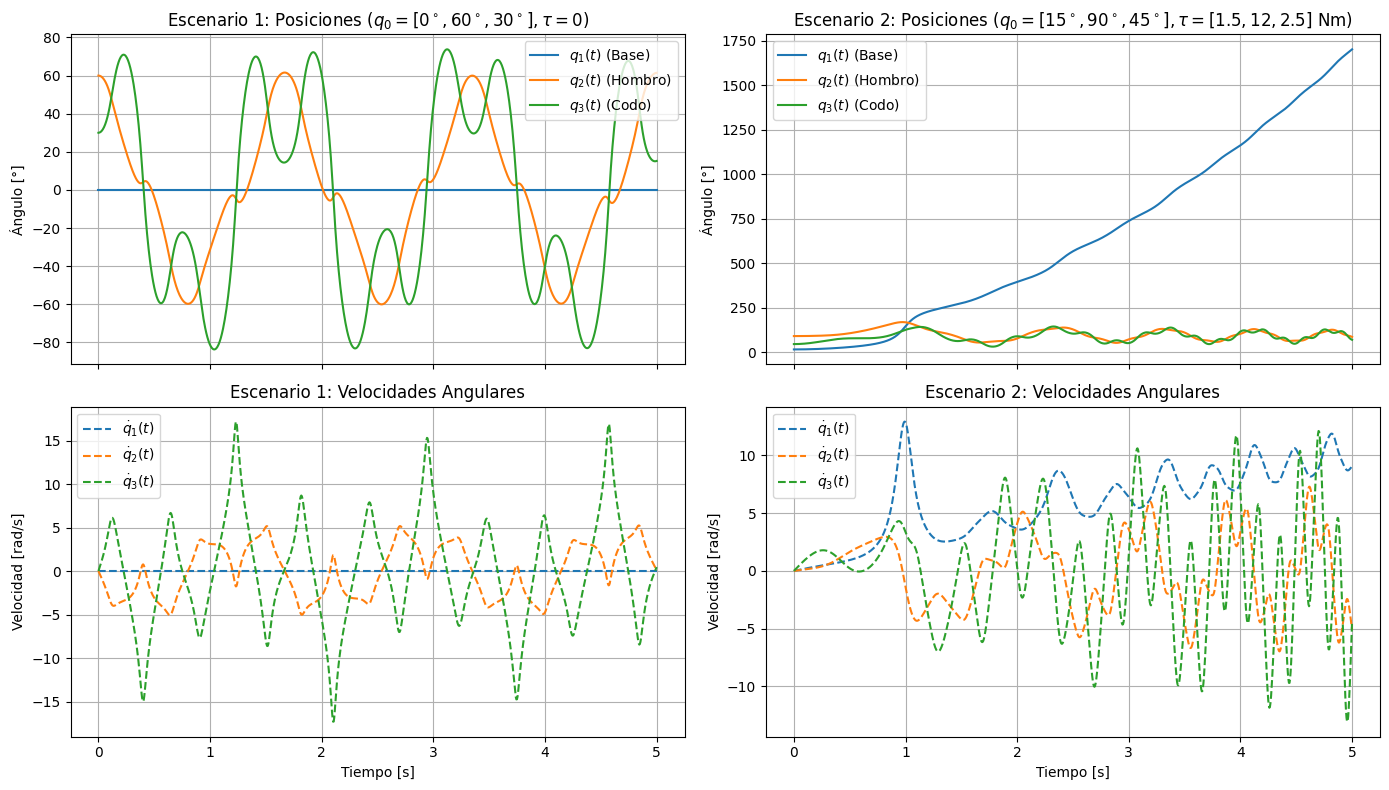

In [ ]:
# Graficación comparativa de ambos escenarios

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)

# Posiciones
axes[0, 0].plot(t, np.degrees(sol_1[:, 0]), label=r'$q_1(t)$ (Base)', color='tab:blue')
axes[0, 0].plot(t, np.degrees(sol_1[:, 1]), label=r'$q_2(t)$ (Hombro)', color='tab:orange')
axes[0, 0].plot(t, np.degrees(sol_1[:, 2]), label=r'$q_3(t)$ (Codo)', color='tab:green')
axes[0, 0].set_title(r'Escenario 1: Posiciones ($q_0=[0^\circ, 60^\circ, 30^\circ], \tau=0$)')
axes[0, 0].set_ylabel('Ángulo [°]')
axes[0, 0].legend(loc='best')
axes[0, 0].grid(True)

# Velocidades
axes[1, 0].plot(t, sol_1[:, 3], label=r'$\dot{q}_1(t)$', color='tab:blue', linestyle='--')
axes[1, 0].plot(t, sol_1[:, 4], label=r'$\dot{q}_2(t)$', color='tab:orange', linestyle='--')
axes[1, 0].plot(t, sol_1[:, 5], label=r'$\dot{q}_3(t)$', color='tab:green', linestyle='--')
axes[1, 0].set_title('Escenario 1: Velocidades Angulares')
axes[1, 0].set_xlabel('Tiempo [s]')
axes[1, 0].set_ylabel('Velocidad [rad/s]')
axes[1, 0].legend(loc='best')
axes[1, 0].grid(True)

# Posiciones 2
axes[0, 1].plot(t, np.degrees(sol_2[:, 0]), label=r'$q_1(t)$ (Base)', color='tab:blue')
axes[0, 1].plot(t, np.degrees(sol_2[:, 1]), label=r'$q_2(t)$ (Hombro)', color='tab:orange')
axes[0, 1].plot(t, np.degrees(sol_2[:, 2]), label=r'$q_3(t)$ (Codo)', color='tab:green')
axes[0, 1].set_title(r'Escenario 2: Posiciones ($q_0=[15^\circ, 90^\circ, 45^\circ], \tau=[1.5, 12, 2.5]$ Nm)')
axes[0, 1].set_ylabel('Ángulo [°]')
axes[0, 1].legend(loc='best')
axes[0, 1].grid(True)

# Velocidades 2
axes[1, 1].plot(t, sol_2[:, 3], label=r'$\dot{q}_1(t)$', color='tab:blue', linestyle='--')
axes[1, 1].plot(t, sol_2[:, 4], label=r'$\dot{q}_2(t)$', color='tab:orange', linestyle='--')
axes[1, 1].plot(t, sol_2[:, 5], label=r'$\dot{q}_3(t)$', color='tab:green', linestyle='--')
axes[1, 1].set_title('Escenario 2: Velocidades Angulares')
axes[1, 1].set_xlabel('Tiempo [s]')
axes[1, 1].set_ylabel('Velocidad [rad/s]')
axes[1, 1].legend(loc='best')
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()